# 04 — Where do abstain / hedge / mirage live, and can they be told apart? (SLAKE, lean)

**Question.** Before building any fix: are the three no-image behaviours represented in the model's state *before it writes anything*, at which layers, is it one vector, how are they arranged, and is the arrangement about the behaviour or about question type?

**Unit of analysis = distinct question text.** Without the image the whole input is system prompt + question text. SLAKE reuses texts across images ("What modality is used to take this image?" ×320), so 3,622 records collapse to **284 distinct inputs**, and 96% of test records' texts also occur in train. A split by image does not separate no-image inputs. Every analysis here uses one row per text (outcome = majority over its records; `unique_texts`) and cross-validates over texts (5-fold, stratified).

**State.** Residual at the last prompt token (before any answer token), Qwen3-VL-4B, without image. Outcomes from the final answer: `abstain` (non-answer), `hedged` (admits missing image, answers anyway), `mirage` (answers, no admission).

**Controls.** Shuffled labels; question-type-only baseline; **type-centred** states (each type's mean removed using training folds only); clustering scored against both outcome and type.

In [1]:
import sys, subprocess, numpy as np, pandas as pd, matplotlib.pyplot as plt
import os; BENCH = os.environ.get('MIRAGE_ROOT', '..'); sys.path.insert(0, '..')  # BENCH: data root with runs/
from miragelab import analysis as A
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', '../tests'], capture_output=True, text=True, cwd='..').stdout[-60:])
df, acts, meta = A.load(BENCH + '/runs/slake'); L = meta['layers']
idx, lab, nrec, stable = A.unique_texts(df)
S = np.asarray(acts[idx, 1, 0], 'f4')                   # [text, layer, d]  no-image pre-answer
cat = df.category.values[idx]; g = np.arange(len(idx))
OUTC = ['abstain', 'hedged', 'mirage']; col = {'abstain': 'tab:blue', 'hedged': 'tab:orange', 'mirage': 'tab:red'}
y3 = np.array([OUTC.index(o) for o in lab])
print('distinct texts', len(idx), '| states', S.shape, '| outcome', pd.Series(lab).value_counts().to_dict(),
      '| texts whose records disagree (vLLM nondeterminism):', int((~stable).sum()))
display(pd.crosstab(cat, lab)[OUTC].assign(texts=pd.Series(cat).value_counts().sort_index().values))

00%]
42 passed in 16.63s

distinct texts 284 | states (284, 18, 2560) | outcome {'mirage': 99, 'hedged': 97, 'abstain': 88} | texts whose records disagree (vLLM nondeterminism): 49


col_0,abstain,hedged,mirage,texts
row_0,,,,
Abnormality,16,0,2,18
Color,2,13,31,46
Modality,4,1,2,7
Organ,0,21,41,62
Plane,0,3,0,3
Position,55,40,13,108
Quantity,1,12,8,21
Shape,10,6,2,18
Size,0,1,0,1


## 1. Where, and are they differentiable?
**Methods.** Logistic probe on the no-image pre-answer state, 5-fold CV over distinct texts, balanced accuracy; every 2nd saved layer. 3-class (chance 0.33) and the three pairs (chance 0.5), raw and type-centred (type means from training folds only). Dashed = shuffled labels. Grey line = question-type-only baseline (3-class).

type-only baseline, 3-class balanced acc: 0.595


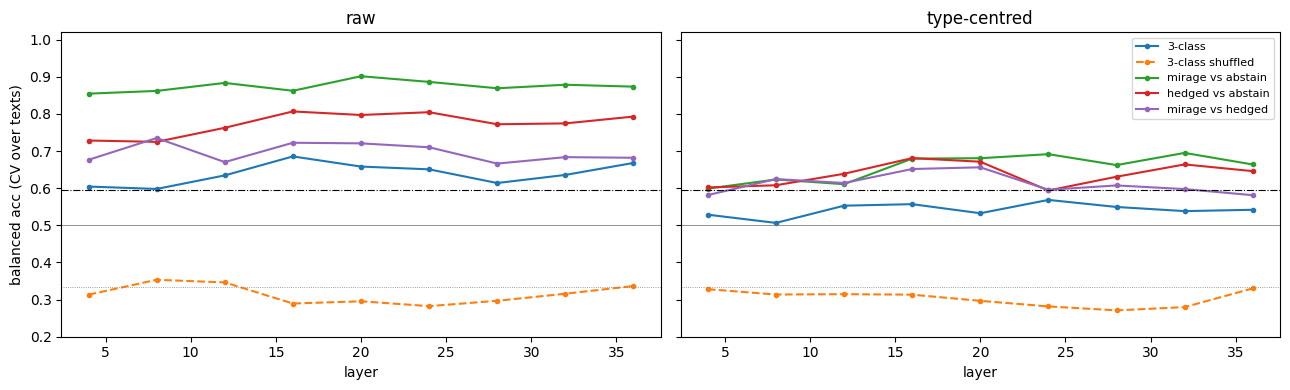

layer                              4      8      12     16     20     24  \
space        probe                                                         
raw          3-class            0.605  0.598  0.635  0.686  0.658  0.651   
             3-class shuffled   0.313  0.353  0.346  0.289  0.295  0.282   
             hedged vs abstain  0.729  0.725  0.763  0.807  0.797  0.805   
             mirage vs abstain  0.855  0.862  0.884  0.863  0.902  0.886   
             mirage vs hedged   0.677  0.735  0.670  0.723  0.721  0.710   
type-centred 3-class            0.529  0.507  0.553  0.557  0.533  0.569   
             3-class shuffled   0.328  0.314  0.315  0.313  0.297  0.282   
             hedged vs abstain  0.602  0.608  0.639  0.681  0.671  0.594   
             mirage vs abstain  0.599  0.624  0.611  0.680  0.681  0.692   
             mirage vs hedged   0.582  0.625  0.614  0.652  0.656  0.596   

layer                              28     32     36  
space        probe                                   
raw          3-class            0.614  0.636  0.668  
             3-class shuffled   0.297  0.316  0.337  
             hedged vs abstain  0.772  0.775  0.793  
             mirage vs abstain  0.869  0.879  0.874  
             mirage vs hedged   0.666  0.684  0.682  
type-centred 3-class            0.550  0.538  0.542  
             3-class shuffled   0.271  0.280  0.330  
             hedged vs abstain  0.631  0.664  0.646  
             mirage vs abstain  0.662  0.695  0.664  
             mirage vs hedged   0.608  0.598  0.581

In [2]:
tb = A.type_baseline_cv(cat, y3, g); print('type-only baseline, 3-class balanced acc: %.3f' % tb)
PAIRS = [('mirage', 'abstain'), ('hedged', 'abstain'), ('mirage', 'hedged')]
rows = []
for j, l in list(enumerate(L))[1::2]:
    for space, cen in [('raw', None), ('type-centred', cat)]:
        rows.append((space, '3-class', l, A.probe_cv(S[:, j], y3, g, center=cen)[0]))
        rows.append((space, '3-class shuffled', l, A.probe_cv(S[:, j], y3, g, center=cen, shuffle_labels=True)[0]))
        for a, b in PAIRS:
            m = np.isin(lab, [a, b])
            rows.append((space, f'{a} vs {b}', l, A.probe_cv(S[m, j], lab[m] == a, g[m], center=None if cen is None else cat[m])[0]))
R = pd.DataFrame(rows, columns=['space', 'probe', 'layer', 'bacc'])
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, space in zip(axs, ['raw', 'type-centred']):
    for name, d in R[R.space == space].groupby('probe', sort=False):
        ax.plot(d.layer, d.bacc, marker='o', ms=3, label=name, ls='--' if 'shuf' in name else '-')
    ax.axhline(.5, c='grey', lw=.6); ax.axhline(1 / 3, c='grey', lw=.6, ls=':'); ax.axhline(tb, c='k', lw=.8, ls='-.')
    ax.set(title=space, xlabel='layer', ylim=(.2, 1.02))
axs[0].set_ylabel('balanced acc (CV over texts)'); axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()
R.pivot_table(index=['space', 'probe'], columns='layer', values='bacc').round(3)

best type-centred 3-class layer: 24 0.569


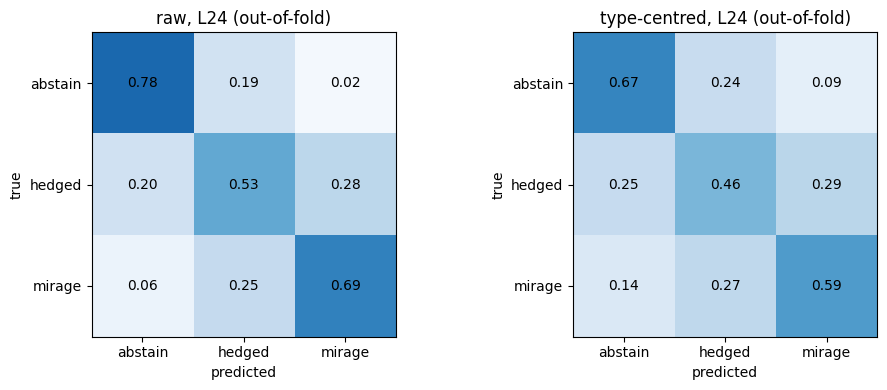

In [3]:
from sklearn.metrics import confusion_matrix
best = R[(R.space == 'type-centred') & (R.probe == '3-class')].sort_values('bacc').iloc[-1]; jb = L.index(int(best.layer))
print('best type-centred 3-class layer:', int(best.layer), round(best.bacc, 3))
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (space, cen) in zip(axs, [('raw', None), ('type-centred', cat)]):
    cm = confusion_matrix(y3, A.probe_oof(S[:, jb], y3, g, center=cen), normalize='true')
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for k in range(3): ax.text(k, i, f'{cm[i, k]:.2f}', ha='center', va='center')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=OUTC, yticklabels=OUTC, xlabel='predicted', ylabel='true', title=f'{space}, L{L[jb]} (out-of-fold)')
plt.tight_layout(); plt.show()

### 1b. How much of it is *one vector*?
**Methods.** One diff-of-means direction per pair, fit on training folds, out-of-fold ROC-AUC of the projection, per layer, raw and type-centred. If one direction approaches the full probe, the behaviour is (mostly) a single linear feature — what a steering vector pushes on.

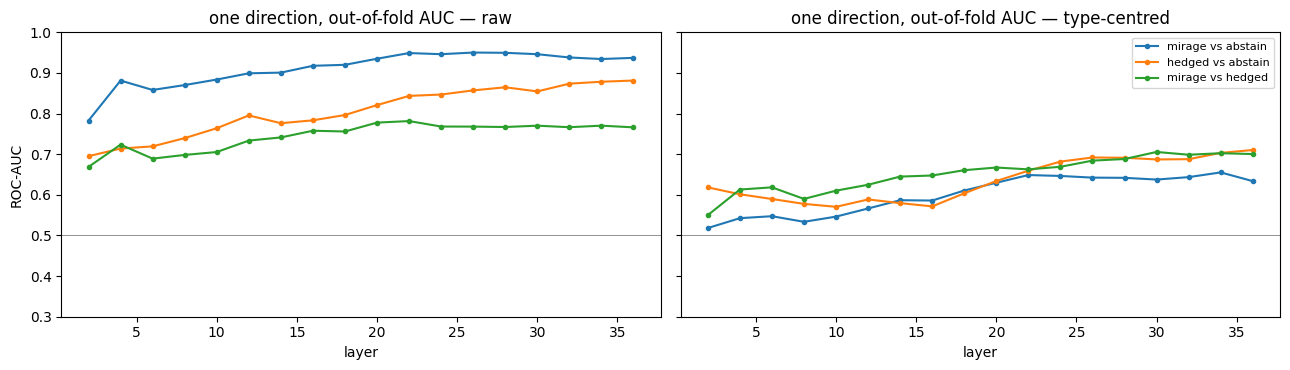

layer    AUC
space        pair                           
raw          hedged vs abstain     36  0.881
             mirage vs abstain     26  0.950
             mirage vs hedged      22  0.782
type-centred hedged vs abstain     36  0.710
             mirage vs abstain     34  0.655
             mirage vs hedged      30  0.706

In [4]:
ov = []
for j, l in enumerate(L):
    for space, cen in [('raw', None), ('type-centred', cat)]:
        for a, b in PAIRS:
            m = np.isin(lab, [a, b])
            ov.append((space, f'{a} vs {b}', l, A.one_vector_auc_cv(S[m, j], lab[m] == a, g[m], center=None if cen is None else cat[m])))
OV = pd.DataFrame(ov, columns=['space', 'pair', 'layer', 'AUC'])
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, space in zip(axs, ['raw', 'type-centred']):
    for name, d in OV[OV.space == space].groupby('pair', sort=False): ax.plot(d.layer, d.AUC, marker='o', ms=3, label=name)
    ax.axhline(.5, c='grey', lw=.6); ax.set(title=f'one direction, out-of-fold AUC — {space}', xlabel='layer', ylim=(.3, 1.0))
axs[0].set_ylabel('ROC-AUC'); axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()
OV.loc[OV.groupby(['space', 'pair']).AUC.idxmax()].set_index(['space', 'pair']).round(3)

**Results.** Question type alone predicts the 3-way outcome at 0.595 balanced accuracy. Raw-state 3-class probes reach 0.60–0.69 (best L16) — little above that baseline. With question type removed inside each fold: 3-class 0.51–0.57 (chance 0.33; shuffled 0.27–0.35); pairs 0.60–0.70 (mirage vs abstain best 0.69–0.70 at L20–32; hedged vs abstain 0.68 at L16; mirage vs hedged 0.66 at L20). One direction, type-centred, out-of-fold AUC: hedged vs abstain 0.71 (L36), mirage vs abstain 0.66 (L34), mirage vs hedged 0.71 (L30). Raw one-direction mirage vs abstain reaches 0.95 — that is mostly question type.

**Discussion.** The behaviours are linearly present before the model speaks, beyond question type, but weakly: ~0.65–0.70 per pair on 284 distinct inputs. Most of what looked like a strong mirage signal is 'what kind of question is this'. A single direction captures about as much as the full probe (one-vector AUC ≈ probe accuracy), so the residual behaviour signal is roughly one-dimensional per pair — steerable in principle, but small.

## 2. How are they arranged? One axis or two?
**Methods (descriptive, all 284 texts).** `axis_position`: where the hedged mean sits on the abstain→mirage line (t: 0 = abstain, 1 = mirage) and how far off it (off, in abstain–mirage distances), per layer, raw and type-centred. Plus the cosine between the mirage−abstain and hedged−abstain directions. One graded axis predicts 0 < t < 1, small off, high cosine.

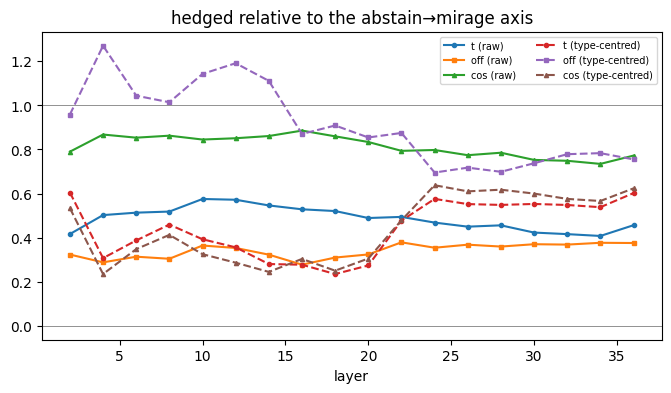

,space,layer,t,off,"cos(m−a, h−a)"
22,raw,24,0.468,0.354,0.798
23,type-centred,24,0.576,0.695,0.638


In [5]:
Sc = np.stack([A.center_by(S[:, j], cat, np.ones(len(S), bool)) for j in range(len(L))], 1)
ax_rows = []
for j, l in enumerate(L):
    for space, X in [('raw', S[:, j]), ('type-centred', Sc[:, j])]:
        t, off = A.axis_position(X, lab)
        vm = A.diff_of_means(X[np.isin(lab, ['mirage', 'abstain'])], lab[np.isin(lab, ['mirage', 'abstain'])] == 'mirage')
        vh = A.diff_of_means(X[np.isin(lab, ['hedged', 'abstain'])], lab[np.isin(lab, ['hedged', 'abstain'])] == 'hedged')
        ax_rows.append((space, l, t, off, float(vm @ vh)))
AX = pd.DataFrame(ax_rows, columns=['space', 'layer', 't', 'off', 'cos(m−a, h−a)'])
fig, ax = plt.subplots(figsize=(8, 4))
for space, d in AX.groupby('space'):
    ls = '-' if space == 'raw' else '--'
    ax.plot(d.layer, d.t, marker='o', ms=3, ls=ls, label=f't ({space})'); ax.plot(d.layer, d.off, marker='s', ms=3, ls=ls, label=f'off ({space})')
    ax.plot(d.layer, d['cos(m−a, h−a)'], marker='^', ms=3, ls=ls, label=f'cos ({space})')
ax.axhline(0, c='grey', lw=.6); ax.axhline(1, c='grey', lw=.6); ax.set(xlabel='layer', title='hedged relative to the abstain→mirage axis'); ax.legend(fontsize=7, ncol=2); plt.show()
AX[AX.layer == L[jb]].round(3)

**Results.** At L24 the hedged mean sits between abstain and mirage (t = 0.47 raw, 0.58 type-centred). Raw: close to the line (off 0.35; cos(mirage−abstain, hedged−abstain) 0.80). Type-centred: well off it (off 0.70; cos 0.64).

**Discussion.** In raw space the three look like one graded 'answer ↔ withhold' axis with hedging halfway. Once question type is removed, hedging has a sizeable component of its own — hedging is not just 'half a mirage'.

## 3. Natural clusters, and which visualisation separates them?
**Methods.** (a) k-means on PCA-20 of the 284 states, no labels: adjusted Rand index against outcome and against question type, k = 3 and k = #types, raw and type-centred, per layer. (b) Five views at the best layer — full 2560-d, PCA, t-SNE, PHATE (unsupervised) and LDA (supervised, fit on these same points: an upper reference built to separate, not evidence of natural clusters) — each scored by kNN purity (k=10; share of neighbours with the same label ÷ share expected from label frequencies; 1 = no grouping), for outcome and for type.

In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score as ari
ntype = len(set(cat)); out = []
for j, l in list(enumerate(L))[1::2]:
    for space, X in [('raw', S[:, j]), ('type-centred', Sc[:, j])]:
        P = PCA(20, random_state=0).fit_transform(X)
        for k in (3, ntype):
            c = KMeans(k, n_init=10, random_state=0).fit_predict(P); out.append((space, k, l, ari(lab, c), ari(cat, c)))
K = pd.DataFrame(out, columns=['space', 'k', 'layer', 'ARI vs outcome', 'ARI vs question type'])
display(K.groupby(['space', 'k'])[['ARI vs outcome', 'ARI vs question type']].max().round(3))
views, sc = {}, []
for space, X in [('raw', S[:, jb]), ('type-centred', Sc[:, jb])]:
    sc.append((space, 'full 2560-d', A.knn_purity(X, lab), A.knn_purity(X, cat)))
    for meth in ['pca', 'tsne', 'phate']:
        Z = A.embed(X, meth); views[(space, meth)] = Z; sc.append((space, meth, A.knn_purity(Z, lab), A.knn_purity(Z, cat)))
    Z, _ = A.lda2(X, y3, X); views[(space, 'lda')] = Z; sc.append((space, 'lda (supervised, in-sample)', A.knn_purity(Z, lab), A.knn_purity(Z, cat)))
SC = pd.DataFrame(sc, columns=['space', 'view', 'purity: outcome', 'purity: question type']); display(SC.round(2))

ARI vs outcome  ARI vs question type
space        k                                      
raw          3           0.178                 0.570
             9           0.133                 0.625
type-centred 3           0.073                 0.008
             9           0.049                 0.066

    SGD-MDS may not have converged: stress changed by -3.4% in final iterations. Consider increasing n_iter or adjusting learning_rate.


,space,view,purity: outcome,purity: question type
0,raw,full 2560-d,1.69,3.79
1,raw,pca,1.68,2.68
2,raw,tsne,1.67,3.75
3,raw,phate,1.65,3.49
4,raw,"lda (supervised, in-sample)",2.95,1.53
5,type-centred,full 2560-d,1.49,2.56
6,type-centred,pca,1.25,1.39
7,type-centred,tsne,1.49,2.71
8,type-centred,phate,1.45,2.72
9,type-centred,"lda (supervised, in-sample)",2.78,2.18


In [ ]:
types = sorted(set(cat)); cmap = plt.get_cmap('tab10')
fig, axs = plt.subplots(3, 4, figsize=(20, 13))
for r, (space, by) in enumerate([('raw', 'outcome'), ('raw', 'type'), ('type-centred', 'outcome')]):
    for c, meth in enumerate(['pca', 'tsne', 'phate', 'lda']):
        Z = views[(space, meth)]; ax = axs[r, c]
        if by == 'outcome':
            for o in OUTC:
                s = lab == o; ax.scatter(Z[s, 0], Z[s, 1], s=14, c=col[o], alpha=.75, label=o)
            pur = SC[(SC.space == space) & SC.view.str.startswith(meth)]['purity: outcome'].values[0]
        else:
            for i, tp in enumerate(types):
                s = cat == tp; ax.scatter(Z[s, 0], Z[s, 1], s=14, color=cmap(i), alpha=.75, label=tp)
            pur = SC[(SC.space == space) & SC.view.str.startswith(meth)]['purity: question type'].values[0]
        ax.set_title(f'{space} · {meth.upper()} · coloured by {by} · purity {pur:.2f}', fontsize=9); ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.legend(fontsize=7, markerscale=1.5)
plt.tight_layout(); plt.show()

**Results.** k-means clusters follow question type (ARI 0.57–0.63), not outcome (0.13–0.18); after removing type, clusters match neither (ARI ≤ 0.07). kNN purity for outcome (1 = no grouping): full space 1.69 raw / 1.49 type-centred; PCA 1.68 / 1.25; t-SNE 1.67 / 1.49; PHATE 1.65 / 1.45. For question type: full 3.79; t-SNE 3.75 and PHATE 3.49 keep it, PCA 2.68 loses some. LDA 2.8–3.0 — but it is fit in-sample on 284 points in 2560-d and separates by construction.

**Discussion.** No visualisation reveals behaviour clusters, because there are none: behaviour is a weak direction inside clusters organised by question type. t-SNE and PHATE preserve the local structure of the full space about equally well (neighbour purity ≈ full space); PCA loses more. PHATE's strength (continuous trajectories) doesn't find a behaviour trajectory here. LDA's clean three-group picture is an in-sample artefact; the honest number is the cross-validated 3-class probe (0.55).

## 4. Discussion

- **Unit:** 284 distinct question texts (the whole no-image input). Earlier per-record numbers were inflated by repeated texts across splits.
- **Is mirage/hedge/abstain represented before speaking?** Yes, beyond question type, but weakly: type-centred pairwise 0.60–0.70, 3-class 0.51–0.57 (chance 0.33). It emerges in middle-to-late layers.
- **Is it a vector?** Roughly: one diff-of-means direction per pair performs about as well as the full probe (type-centred AUC 0.66–0.71).
- **Geometry:** the dominant structure is question type. Behaviour is a weak direction inside type clusters, not its own cluster. Hedging is intermediate and, with type removed, partly its own direction.
- **Visualisation:** none of PCA / t-SNE / PHATE separates behaviour beyond the full space; t-SNE and PHATE preserve neighbourhoods best; LDA separates only in-sample.
- **Implication for steering (notebook 03):** a vector exists but is small relative to question-type structure; expect modest, type-dependent effects. The type-centred vector arm tests whether any effect is behaviour rather than type.
- **Limits:** 284 inputs; one model; outcome labels from regex on the final answer; 49 texts had inconsistent outcomes across repeated vLLM calls (majority label used).